In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("All libraries imported successfully!")


All libraries imported successfully!


# Electrical Signal Analysis and Automated Validation

## Project Overview

This project develops a Python-based electrical signal
analysis and validation tool.

The program will:

1. Generate a simulated electrical signal.
2. Introduce random electrical noise.
3. Calculate signal characteristics.
4. Visualize time-domain and frequency-domain signals.
5. Evaluate signal quality against predefined specifications.
6. Automatically generate a validation report.

## Tools
- Python
- NumPy
- Matplotlib
- Pandas

## Engineering Applications
- Electrical signal characterization
- Signal integrity analysis
- Automated test validation
- Measurement data analysis

## Step 2: Electrical Signal Generation

### Objective
Generate a sinusoidal voltage waveform using Python and NumPy.

### Signal Specifications
- Peak Amplitude: 1 V
- Frequency: 1000 Hz (1 kHz)
- Sampling Frequency: 100,000 Hz (100 kHz)
- Signal Duration: 0.01 seconds (10 ms)

### Mathematical Model

V(t) = A sin(2πft)

The generated signal will serve as the reference waveform
for subsequent noise analysis and electrical validation.


In [3]:
# Step 2.1: Define electrical signal parameters

amplitude = 1.0          # Peak voltage (V)
frequency = 1000         # Signal frequency (Hz)
sampling_rate = 100000   # Samples per second (Hz)
duration = 0.01          # Signal duration (seconds)

# Calculate total number of samples
num_samples = int(sampling_rate * duration)

print("Signal Parameters:")
print(f"Amplitude: {amplitude} V")
print(f"Frequency: {frequency} Hz")
print(f"Sampling Rate: {sampling_rate} Hz")
print(f"Duration: {duration} seconds")
print(f"Total Samples: {num_samples}")

Signal Parameters:
Amplitude: 1.0 V
Frequency: 1000 Hz
Sampling Rate: 100000 Hz
Duration: 0.01 seconds
Total Samples: 1000


In [4]:
# Step 2.2: Generate time values

time = np.arange(num_samples) / sampling_rate

print("First 10 time samples:")
print(time[:10])

print(f"\nTotal time samples: {len(time)}")

First 10 time samples:
[0.e+00 1.e-05 2.e-05 3.e-05 4.e-05 5.e-05 6.e-05 7.e-05 8.e-05 9.e-05]

Total time samples: 1000


In [5]:
# Step 2.3: Generate the sinusoidal signal

signal = amplitude * np.sin(2 * np.pi * frequency * time)

print("First 10 voltage samples:")
print(signal[:10])

print(f"\nNumber of voltage samples: {len(signal)}")

First 10 voltage samples:
[0.         0.06279052 0.12533323 0.18738131 0.24868989 0.30901699
 0.36812455 0.42577929 0.48175367 0.53582679]

Number of voltage samples: 1000


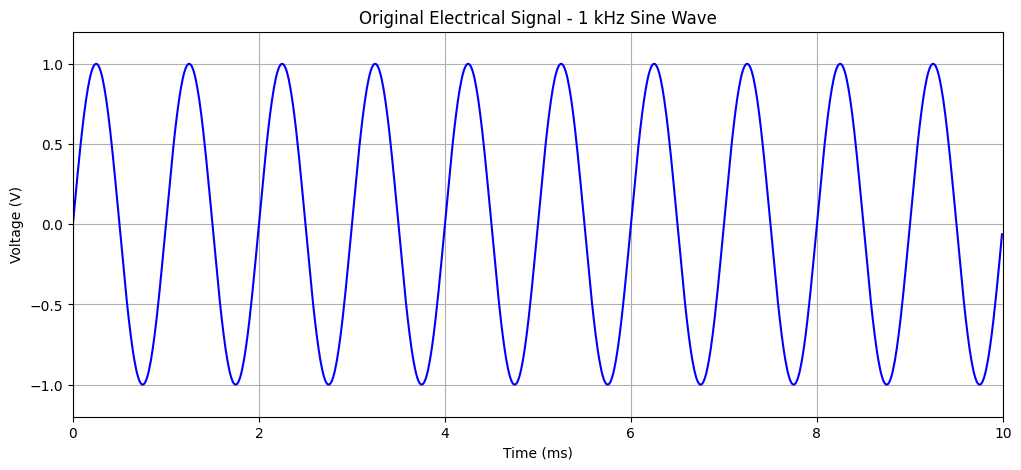

In [6]:
# Step 2.4: Visualize the generated signal

plt.figure(figsize=(12, 5))

plt.plot(time * 1000, signal, color='blue', linewidth=1.5)

plt.title("Original Electrical Signal - 1 kHz Sine Wave")
plt.xlabel("Time (ms)")
plt.ylabel("Voltage (V)")

plt.grid(True)
plt.xlim(0, 10)
plt.ylim(-1.2, 1.2)

plt.show()

In [7]:
# Step 2.5: Verify generated signal

max_voltage = np.max(signal)
min_voltage = np.min(signal)

peak_to_peak = max_voltage - min_voltage

print("Signal Verification Results:")
print(f"Maximum Voltage: {max_voltage:.4f} V")
print(f"Minimum Voltage: {min_voltage:.4f} V")
print(f"Peak-to-Peak Voltage: {peak_to_peak:.4f} V")
print(f"Expected Number of Cycles: {frequency * duration}")

Signal Verification Results:
Maximum Voltage: 1.0000 V
Minimum Voltage: -1.0000 V
Peak-to-Peak Voltage: 2.0000 V
Expected Number of Cycles: 10.0


## Step 3: Electrical Noise Simulation

### Objective
Simulate electrical measurement noise and analyze its
effect on a sinusoidal voltage signal.

### Noise Model
V_measured(t) = V_signal(t) + N(t)

Where:
- V_measured(t): Measured voltage
- V_signal(t): Original sinusoidal signal
- N(t): Random Gaussian noise

### Noise Specifications
- Noise Type: Gaussian (Normal Distribution)
- Noise Mean: 0 V
- Noise Standard Deviation: 0.1 V
- Number of Samples: 1000

### Engineering Relevance
Electrical noise can affect signal integrity, measurement
accuracy, and communication system performance.

This simulation demonstrates how random noise influences
electrical measurements.

In [8]:
# Step 3.1: Generate random electrical noise

noise_mean = 0
noise_std = 0.1

# Set random seed for reproducible results
np.random.seed(42)

# Generate Gaussian noise
noise = np.random.normal(
    loc=noise_mean,
    scale=noise_std,
    size=num_samples
)

print("Noise Generation Results:")
print(f"Number of Noise Samples: {len(noise)}")
print(f"Noise Mean: {np.mean(noise):.4f} V")
print(f"Noise Standard Deviation: {np.std(noise):.4f} V")
print(f"Maximum Noise Voltage: {np.max(noise):.4f} V")
print(f"Minimum Noise Voltage: {np.min(noise):.4f} V")

Noise Generation Results:
Number of Noise Samples: 1000
Noise Mean: 0.0019 V
Noise Standard Deviation: 0.0979 V
Maximum Noise Voltage: 0.3853 V
Minimum Noise Voltage: -0.3241 V


In [9]:
# Step 3.2: Add noise to the original signal

measured_signal = signal + noise

print("Signal Comparison:")
print(f"Original Signal Samples: {len(signal)}")
print(f"Noise Samples: {len(noise)}")
print(f"Measured Signal Samples: {len(measured_signal)}")

print("\nFirst 10 Measured Voltage Samples:")
print(measured_signal[:10])

Signal Comparison:
Original Signal Samples: 1000
Noise Samples: 1000
Measured Signal Samples: 1000

First 10 Measured Voltage Samples:
[0.04967142 0.04896409 0.19010209 0.3396843  0.22527455 0.2856033
 0.52604583 0.50252276 0.43480624 0.5900828 ]


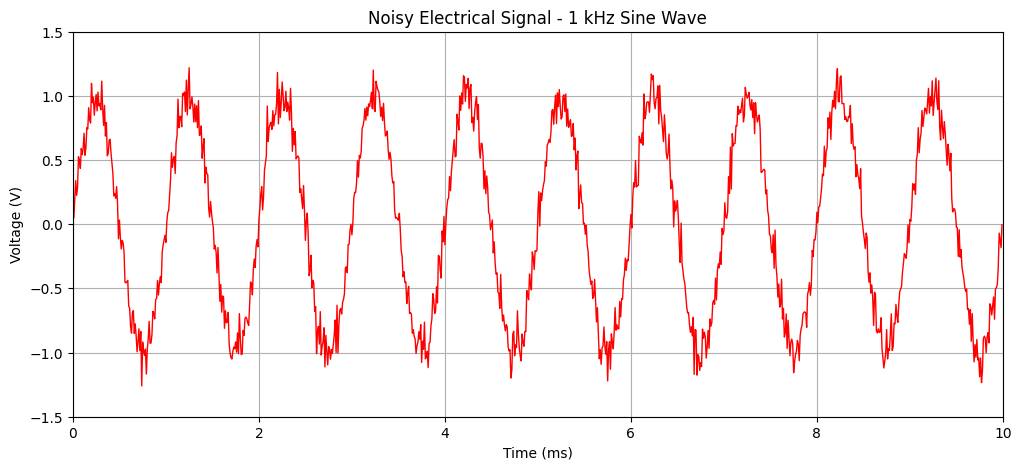

In [10]:
# Step 3.3: Plot the noisy electrical signal

plt.figure(figsize=(12, 5))

plt.plot(
    time * 1000,
    measured_signal,
    color='red',
    linewidth=1
)

plt.title("Noisy Electrical Signal - 1 kHz Sine Wave")
plt.xlabel("Time (ms)")
plt.ylabel("Voltage (V)")

plt.grid(True)
plt.xlim(0, 10)
plt.ylim(-1.5, 1.5)

plt.show()

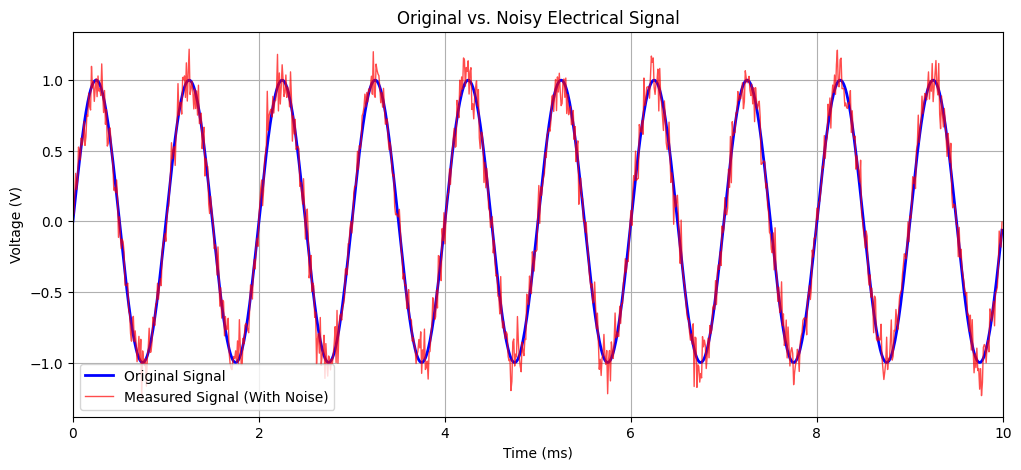

In [11]:
# Step 3.4: Compare original and noisy signals

plt.figure(figsize=(12, 5))

# Original signal
plt.plot(
    time * 1000,
    signal,
    color='blue',
    linewidth=2,
    label='Original Signal'
)

# Noisy signal
plt.plot(
    time * 1000,
    measured_signal,
    color='red',
    linewidth=1,
    alpha=0.7,
    label='Measured Signal (With Noise)'
)

plt.title("Original vs. Noisy Electrical Signal")
plt.xlabel("Time (ms)")
plt.ylabel("Voltage (V)")

plt.legend()
plt.grid(True)
plt.xlim(0, 10)

plt.show()

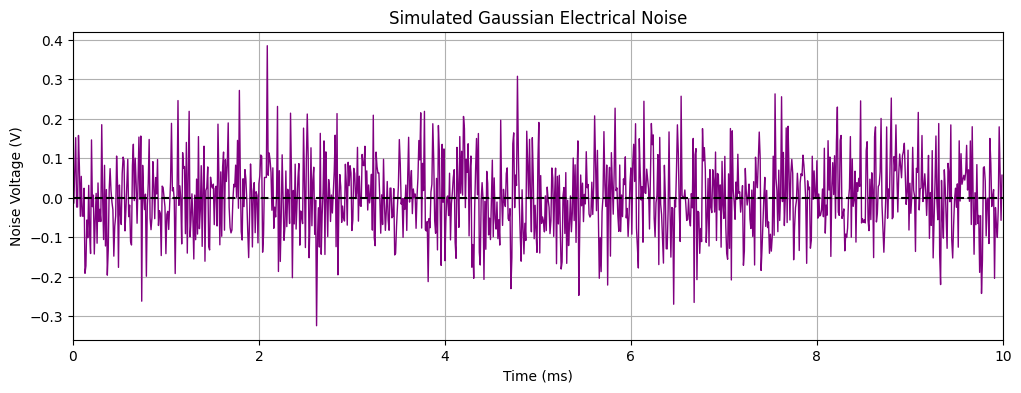

In [12]:
# Step 3.5: Visualize electrical noise

plt.figure(figsize=(12, 4))

plt.plot(
    time * 1000,
    noise,
    color='purple',
    linewidth=1
)

plt.title("Simulated Gaussian Electrical Noise")
plt.xlabel("Time (ms)")
plt.ylabel("Noise Voltage (V)")

plt.axhline(0, color='black', linestyle='--')

plt.grid(True)
plt.xlim(0, 10)

plt.show()

## Step 4: Electrical Signal Measurements and SNR Analysis

### Objective
Calculate important electrical signal characteristics
and evaluate the effect of Gaussian noise on signal quality.

### Measurements
1. Peak Voltage
2. RMS Voltage
3. Average Voltage
4. Noise RMS
5. Signal-to-Noise Ratio (SNR)

### Mathematical Models

RMS Voltage:
V_RMS = sqrt(mean(V²))

Average Voltage:
V_avg = mean(V)

Noise RMS:
V_noise,RMS = sqrt(mean(N²))

Signal-to-Noise Ratio:
SNR_dB = 20 × log10(V_signal,RMS / V_noise,RMS)

### Engineering Relevance
These measurements help engineers evaluate signal quality,
quantify electrical noise, and investigate unexpected
measurement behavior.

In [13]:
# Step 4.1: Calculate peak voltage

original_peak = np.max(signal)
measured_peak = np.max(measured_signal)

original_min = np.min(signal)
measured_min = np.min(measured_signal)

print("Peak Voltage Analysis:")
print(f"Original Peak Voltage: {original_peak:.4f} V")
print(f"Measured Peak Voltage: {measured_peak:.4f} V")

print(f"\nOriginal Minimum Voltage: {original_min:.4f} V")
print(f"Measured Minimum Voltage: {measured_min:.4f} V")

Peak Voltage Analysis:
Original Peak Voltage: 1.0000 V
Measured Peak Voltage: 1.2190 V

Original Minimum Voltage: -1.0000 V
Measured Minimum Voltage: -1.2600 V


In [14]:
# Step 4.2: Calculate RMS voltage

original_rms = np.sqrt(np.mean(signal**2))

measured_rms = np.sqrt(np.mean(measured_signal**2))

theoretical_rms = amplitude / np.sqrt(2)

print("RMS Voltage Analysis:")
print(f"Theoretical RMS Voltage: {theoretical_rms:.4f} V")
print(f"Original Signal RMS: {original_rms:.4f} V")
print(f"Measured Signal RMS: {measured_rms:.4f} V")

RMS Voltage Analysis:
Theoretical RMS Voltage: 0.7071 V
Original Signal RMS: 0.7071 V
Measured Signal RMS: 0.7100 V


In [15]:
# Step 4.3: Calculate average voltage

original_average = np.mean(signal)

measured_average = np.mean(measured_signal)

print("Average Voltage Analysis:")
print(f"Original Average Voltage: {original_average:.6f} V")
print(f"Measured Average Voltage: {measured_average:.6f} V")

Average Voltage Analysis:
Original Average Voltage: -0.000000 V
Measured Average Voltage: 0.001933 V


In [16]:
# Step 4.4: Calculate noise RMS

# Extract noise from measured signal
extracted_noise = measured_signal - signal

# Calculate noise RMS
noise_rms = np.sqrt(np.mean(extracted_noise**2))

print("Noise RMS Analysis:")
print(f"Noise RMS Voltage: {noise_rms:.4f} V")
print(f"Noise Standard Deviation: {np.std(noise):.4f} V")

Noise RMS Analysis:
Noise RMS Voltage: 0.0979 V
Noise Standard Deviation: 0.0979 V


In [17]:
# Step 4.5: Calculate Signal-to-Noise Ratio

snr_ratio = original_rms / noise_rms

snr_db = 20 * np.log10(snr_ratio)

print("Signal-to-Noise Ratio Analysis:")
print(f"Signal RMS: {original_rms:.4f} V")
print(f"Noise RMS: {noise_rms:.4f} V")
print(f"SNR Ratio: {snr_ratio:.4f}")
print(f"SNR: {snr_db:.2f} dB")

Signal-to-Noise Ratio Analysis:
Signal RMS: 0.7071 V
Noise RMS: 0.0979 V
SNR Ratio: 7.2234
SNR: 17.17 dB


In [18]:
# Step 4.6: Display measurement summary

print("=" * 50)
print("ELECTRICAL SIGNAL MEASUREMENT SUMMARY")
print("=" * 50)

print(f"Signal Frequency:       {frequency} Hz")
print(f"Sampling Rate:          {sampling_rate} Hz")
print(f"Original Peak Voltage:  {original_peak:.4f} V")
print(f"Measured Peak Voltage:  {measured_peak:.4f} V")
print(f"Original RMS Voltage:   {original_rms:.4f} V")
print(f"Measured RMS Voltage:   {measured_rms:.4f} V")
print(f"Original Average:       {original_average:.6f} V")
print(f"Measured Average:       {measured_average:.6f} V")
print(f"Noise RMS:              {noise_rms:.4f} V")
print(f"Signal-to-Noise Ratio:  {snr_db:.2f} dB")

print("=" * 50)

ELECTRICAL SIGNAL MEASUREMENT SUMMARY
Signal Frequency:       1000 Hz
Sampling Rate:          100000 Hz
Original Peak Voltage:  1.0000 V
Measured Peak Voltage:  1.2190 V
Original RMS Voltage:   0.7071 V
Measured RMS Voltage:   0.7100 V
Original Average:       -0.000000 V
Measured Average:       0.001933 V
Noise RMS:              0.0979 V
Signal-to-Noise Ratio:  17.17 dB


## Step 5: Frequency-Domain Analysis Using FFT

### Objective
Analyze the frequency components of the original and
measured electrical signals using the Fast Fourier Transform.

### Signal Specifications
- Signal Frequency: 1000 Hz
- Sampling Frequency: 100,000 Hz
- Number of Samples: 1000
- Signal Duration: 0.01 seconds

### Analysis Methods
1. Compute the Fast Fourier Transform (FFT).
2. Generate the frequency axis.
3. Calculate the amplitude spectrum.
4. Identify the dominant signal frequency.
5. Compare the original and noisy signal spectra.

### Engineering Relevance
Frequency-domain analysis helps engineers identify
signal frequencies, detect interference, and investigate
unexpected spectral components in electrical measurements.

In [19]:
# Step 5.1: Compute FFT of original signal

original_fft = np.fft.rfft(signal)

# Generate frequency axis
fft_frequencies = np.fft.rfftfreq(
    num_samples,
    d=1 / sampling_rate
)

print("FFT Analysis:")
print(f"Number of Time Samples: {num_samples}")
print(f"Number of Frequency Bins: {len(fft_frequencies)}")
print(f"Maximum Frequency: {fft_frequencies[-1]:.0f} Hz")

FFT Analysis:
Number of Time Samples: 1000
Number of Frequency Bins: 501
Maximum Frequency: 50000 Hz


In [20]:
# Step 5.2: Calculate original signal amplitude spectrum

original_spectrum = np.abs(original_fft) / num_samples

# Convert to one-sided amplitude spectrum
original_spectrum[1:-1] *= 2

print("Amplitude Spectrum Calculated Successfully!")

Amplitude Spectrum Calculated Successfully!


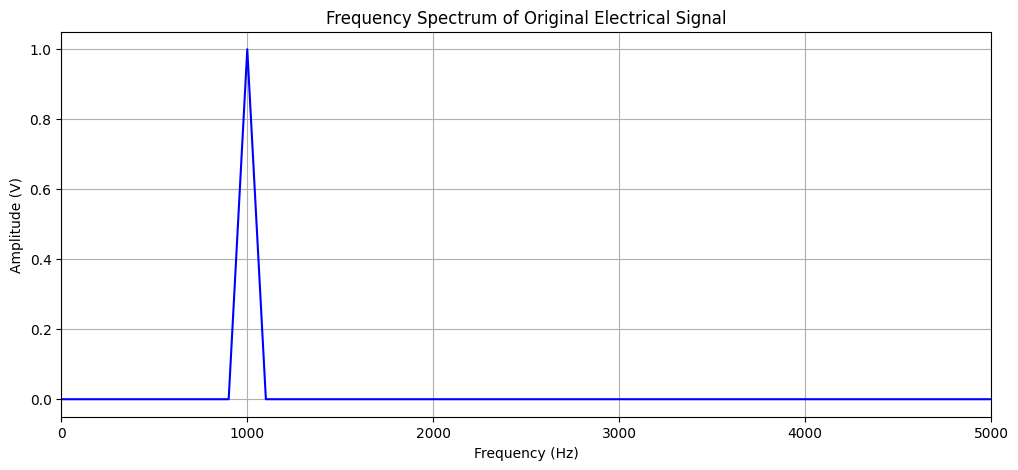

In [21]:
# Step 5.3: Plot original signal frequency spectrum

plt.figure(figsize=(12, 5))

plt.plot(
    fft_frequencies,
    original_spectrum,
    color='blue',
    linewidth=1.5
)

plt.title("Frequency Spectrum of Original Electrical Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (V)")

plt.grid(True)
plt.xlim(0, 5000)

plt.show()

In [22]:
# Step 5.4: Compute FFT of measured signal

measured_fft = np.fft.rfft(measured_signal)

measured_spectrum = np.abs(measured_fft) / num_samples

# Convert to one-sided amplitude spectrum
measured_spectrum[1:-1] *= 2

print("Measured Signal FFT Calculated Successfully!")

Measured Signal FFT Calculated Successfully!


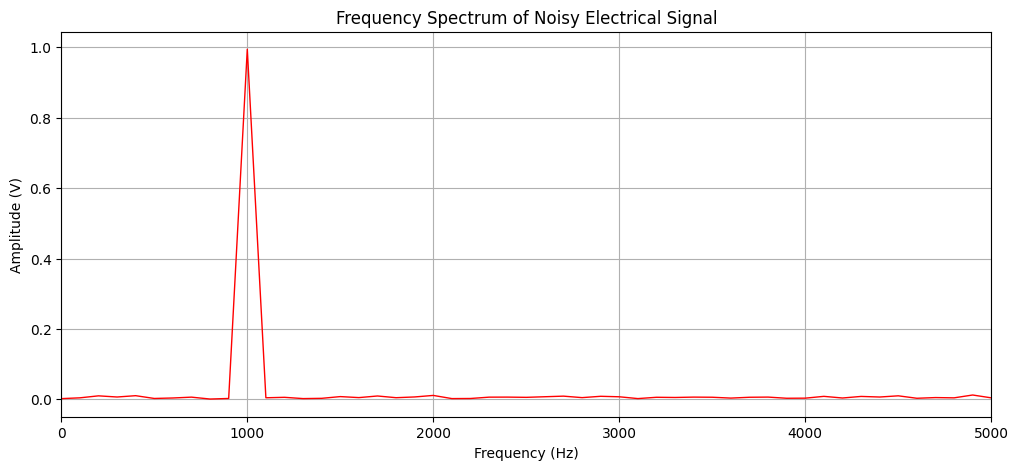

In [23]:
# Step 5.5: Plot noisy signal frequency spectrum

plt.figure(figsize=(12, 5))

plt.plot(
    fft_frequencies,
    measured_spectrum,
    color='red',
    linewidth=1
)

plt.title("Frequency Spectrum of Noisy Electrical Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (V)")

plt.grid(True)
plt.xlim(0, 5000)

plt.show()

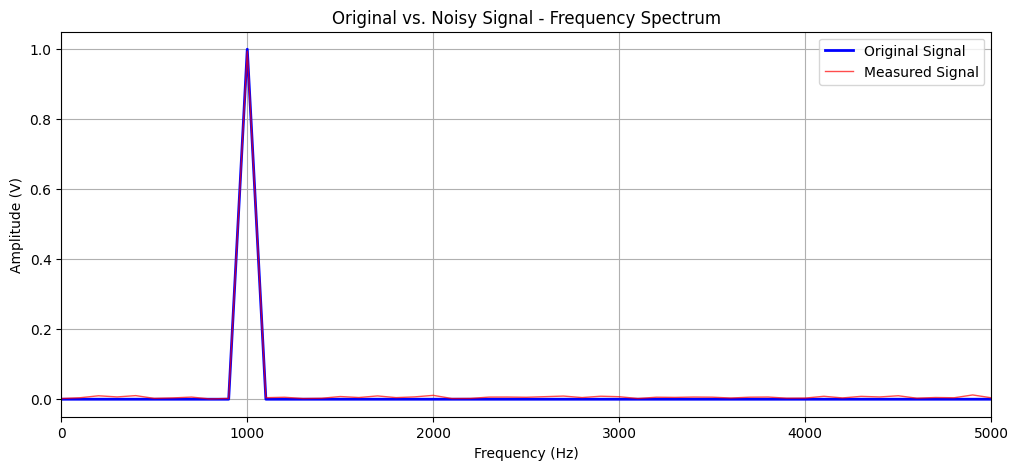

In [24]:
# Step 5.6: Compare original and measured frequency spectra

plt.figure(figsize=(12, 5))

plt.plot(
    fft_frequencies,
    original_spectrum,
    color='blue',
    linewidth=2,
    label='Original Signal'
)

plt.plot(
    fft_frequencies,
    measured_spectrum,
    color='red',
    linewidth=1,
    alpha=0.7,
    label='Measured Signal'
)

plt.title("Original vs. Noisy Signal - Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (V)")

plt.legend()
plt.grid(True)
plt.xlim(0, 5000)

plt.show()

In [25]:
# Step 5.7: Identify dominant signal frequency

# Exclude DC component
dominant_index = np.argmax(measured_spectrum[1:]) + 1

# Determine dominant frequency and amplitude
dominant_frequency = fft_frequencies[dominant_index]

dominant_amplitude = measured_spectrum[dominant_index]

print("Dominant Frequency Analysis:")
print(f"Expected Frequency: {frequency} Hz")
print(f"Detected Frequency: {dominant_frequency:.2f} Hz")
print(f"Detected Amplitude: {dominant_amplitude:.4f} V")

Dominant Frequency Analysis:
Expected Frequency: 1000 Hz
Detected Frequency: 1000.00 Hz
Detected Amplitude: 0.9946 V


In [26]:
# Step 5.8: Frequency analysis summary

frequency_error = abs(dominant_frequency - frequency)

print("=" * 50)
print("FREQUENCY-DOMAIN ANALYSIS SUMMARY")
print("=" * 50)

print(f"Expected Signal Frequency: {frequency} Hz")
print(f"Detected Signal Frequency: {dominant_frequency:.2f} Hz")
print(f"Frequency Error: {frequency_error:.2f} Hz")
print(f"Dominant FFT Amplitude: {dominant_amplitude:.4f} V")
print(f"Frequency Resolution: {sampling_rate / num_samples:.2f} Hz")
print(f"Nyquist Frequency: {sampling_rate / 2:.2f} Hz")

print("=" * 50)

FREQUENCY-DOMAIN ANALYSIS SUMMARY
Expected Signal Frequency: 1000 Hz
Detected Signal Frequency: 1000.00 Hz
Frequency Error: 0.00 Hz
Dominant FFT Amplitude: 0.9946 V
Frequency Resolution: 100.00 Hz
Nyquist Frequency: 50000.00 Hz


## Step 6: Automated Electrical Signal Validation

### Objective
Develop an automated validation system that compares
simulated electrical measurements against predefined
engineering specifications.

### Validation Requirements

| Parameter | Acceptance Criteria |
|---|---|
| Signal Frequency | 1000 ± 50 Hz |
| Signal-to-Noise Ratio | ≥ 20 dB |
| Maximum Absolute Voltage | ≤ 1.20 V |
| RMS Voltage | 0.65–0.75 V |
| Average Voltage | -0.05 to +0.05 V |

### Validation Methodology
1. Define engineering specifications.
2. Compare measured values against acceptable limits.
3. Assign PASS or FAIL to each measurement.
4. Calculate the overall validation result.
5. Generate a structured validation report.

### Engineering Relevance
Automated validation reduces repetitive manual analysis,
improves testing consistency, and helps engineers
identify measurements that violate system specifications.

Note: The acceptance limits used in this project are
illustrative and are not based on a commercial device.

In [27]:
# Step 6.1: Define electrical validation specifications

specifications = {
    "expected_frequency": 1000,
    "frequency_tolerance": 50,
    "minimum_snr": 20,
    "maximum_absolute_voltage": 1.20,
    "minimum_rms": 0.65,
    "maximum_rms": 0.75,
    "minimum_average": -0.05,
    "maximum_average": 0.05
}

print("Electrical Validation Specifications")
print("=" * 45)

for parameter, value in specifications.items():
    print(f"{parameter}: {value}")

Electrical Validation Specifications
expected_frequency: 1000
frequency_tolerance: 50
minimum_snr: 20
maximum_absolute_voltage: 1.2
minimum_rms: 0.65
maximum_rms: 0.75
minimum_average: -0.05
maximum_average: 0.05


In [28]:
# Step 6.2: Create automated validation function

def validate_measurement(
    measurement_name,
    measured_value,
    minimum=None,
    maximum=None
):

    passed = True

    if minimum is not None:
        if measured_value < minimum:
            passed = False

    if maximum is not None:
        if measured_value > maximum:
            passed = False

    status = "PASS" if passed else "FAIL"

    return {
        "Measurement": measurement_name,
        "Measured Value": measured_value,
        "Minimum Limit": minimum,
        "Maximum Limit": maximum,
        "Status": status
    }


print("Automated Validation Function Created Successfully!")

Automated Validation Function Created Successfully!


In [29]:
# Step 6.3: Validate signal frequency

frequency_validation = validate_measurement(
    "Signal Frequency",
    dominant_frequency,
    minimum=specifications["expected_frequency"]
            - specifications["frequency_tolerance"],
    maximum=specifications["expected_frequency"]
            + specifications["frequency_tolerance"]
)

print("Frequency Validation Result:")
print(frequency_validation)

Frequency Validation Result:
{'Measurement': 'Signal Frequency', 'Measured Value': np.float64(1000.0), 'Minimum Limit': 950, 'Maximum Limit': 1050, 'Status': 'PASS'}


In [30]:
# Step 6.4: Validate signal-to-noise ratio

snr_validation = validate_measurement(
    "Signal-to-Noise Ratio",
    snr_db,
    minimum=specifications["minimum_snr"]
)

print("SNR Validation Result:")
print(snr_validation)

SNR Validation Result:
{'Measurement': 'Signal-to-Noise Ratio', 'Measured Value': np.float64(17.174781610884892), 'Minimum Limit': 20, 'Maximum Limit': None, 'Status': 'FAIL'}


In [31]:
# Step 6.5: Validate maximum absolute voltage

maximum_absolute_voltage = np.max(
    np.abs(measured_signal)
)

voltage_validation = validate_measurement(
    "Maximum Absolute Voltage",
    maximum_absolute_voltage,
    maximum=specifications["maximum_absolute_voltage"]
)

print("Voltage Validation Result:")
print(voltage_validation)

Voltage Validation Result:
{'Measurement': 'Maximum Absolute Voltage', 'Measured Value': np.float64(1.260001238837246), 'Minimum Limit': None, 'Maximum Limit': 1.2, 'Status': 'FAIL'}


In [32]:
# Step 6.6: Validate RMS voltage

rms_validation = validate_measurement(
    "RMS Voltage",
    measured_rms,
    minimum=specifications["minimum_rms"],
    maximum=specifications["maximum_rms"]
)

print("RMS Validation Result:")
print(rms_validation)

RMS Validation Result:
{'Measurement': 'RMS Voltage', 'Measured Value': np.float64(0.7100434767406562), 'Minimum Limit': 0.65, 'Maximum Limit': 0.75, 'Status': 'PASS'}


In [33]:
# Step 6.7: Validate average voltage

average_validation = validate_measurement(
    "Average Voltage",
    measured_average,
    minimum=specifications["minimum_average"],
    maximum=specifications["maximum_average"]
)

print("Average Voltage Validation Result:")
print(average_validation)

Average Voltage Validation Result:
{'Measurement': 'Average Voltage', 'Measured Value': np.float64(0.0019332055822325316), 'Minimum Limit': -0.05, 'Maximum Limit': 0.05, 'Status': 'PASS'}


In [34]:
# Step 6.8: Generate automated validation report

validation_results = [
    frequency_validation,
    snr_validation,
    voltage_validation,
    rms_validation,
    average_validation
]

validation_df = pd.DataFrame(validation_results)

print("AUTOMATED ELECTRICAL VALIDATION REPORT")
print("=" * 60)

display(validation_df)

AUTOMATED ELECTRICAL VALIDATION REPORT


,Measurement,Measured Value,Minimum Limit,Maximum Limit,Status
0,Signal Frequency,1000.000000,950.00,1050.00,PASS
1,Signal-to-Noise Ratio,17.174782,20.00,NaN,FAIL
2,Maximum Absolute Voltage,1.260001,NaN,1.20,FAIL
3,RMS Voltage,0.710043,0.65,0.75,PASS
4,Average Voltage,0.001933,-0.05,0.05,PASS


In [35]:
# Step 6.9: Calculate overall validation result

total_tests = len(validation_df)

passed_tests = (
    validation_df["Status"] == "PASS"
).sum()

failed_tests = (
    validation_df["Status"] == "FAIL"
).sum()

pass_percentage = (passed_tests / total_tests) * 100

overall_status = (
    "PASS" if failed_tests == 0 else "FAIL"
)

print("=" * 55)
print("AUTOMATED ELECTRICAL SIGNAL VALIDATION SUMMARY")
print("=" * 55)

print(f"Total Tests: {total_tests}")
print(f"Passed Tests: {passed_tests}")
print(f"Failed Tests: {failed_tests}")
print(f"Pass Percentage: {pass_percentage:.2f}%")

print("-" * 55)

print(f"OVERALL VALIDATION STATUS: {overall_status}")

print("=" * 55)

AUTOMATED ELECTRICAL SIGNAL VALIDATION SUMMARY
Total Tests: 5
Passed Tests: 3
Failed Tests: 2
Pass Percentage: 60.00%
-------------------------------------------------------
OVERALL VALIDATION STATUS: FAIL


# Step 7: Automated Report Generation and Data Export

## Objective

Develop an automated reporting system that exports electrical
signal measurements, validation results, and engineering test
summaries.

## Report Components

1. Time-domain signal measurement dataset.
2. Electrical validation results.
3. Overall test summary.
4. Identification of failed measurements.
5. Visualization of validation outcomes.

## Output Files

- electrical_signal_measurements.csv
- electrical_validation_results.csv
- electrical_validation_summary.txt

## Engineering Relevance

Automated reporting enables engineers to document test
results, identify specification violations, and analyze
measurement data efficiently.

Exporting structured data also allows test results to be
shared, reviewed, and processed by other engineering tools.

In [36]:
# Step 7.1: Create electrical measurement dataset

measurement_data = pd.DataFrame({
    "Time (s)": time,
    "Original Voltage (V)": signal,
    "Noise Voltage (V)": noise,
    "Measured Voltage (V)": measured_signal
})

print("Electrical Measurement Dataset")
print("=" * 50)

display(measurement_data.head(10))

print(f"\nTotal Measurement Samples: {len(measurement_data)}")

Electrical Measurement Dataset


,Time (s),Original Voltage (V),Noise Voltage (V),Measured Voltage (V)
0,0.00000,0.000000,0.049671,0.049671
1,0.00001,0.062791,-0.013826,0.048964
2,0.00002,0.125333,0.064769,0.190102
3,0.00003,0.187381,0.152303,0.339684
4,0.00004,0.248690,-0.023415,0.225275
5,0.00005,0.309017,-0.023414,0.285603
6,0.00006,0.368125,0.157921,0.526046
7,0.00007,0.425779,0.076743,0.502523
8,0.00008,0.481754,-0.046947,0.434806
9,0.00009,0.535827,0.054256,0.590083



Total Measurement Samples: 1000


In [37]:
# Step 7.2: Export electrical measurement data

measurement_filename = "electrical_signal_measurements.csv"

measurement_data.to_csv(
    measurement_filename,
    index=False
)

print("Measurement Data Exported Successfully!")
print(f"Filename: {measurement_filename}")
print(f"Total Samples Exported: {len(measurement_data)}")

Measurement Data Exported Successfully!
Filename: electrical_signal_measurements.csv
Total Samples Exported: 1000


In [38]:
# Step 7.3: Export automated validation results

validation_filename = "electrical_validation_results.csv"

validation_df.to_csv(
    validation_filename,
    index=False
)

print("Validation Results Exported Successfully!")
print(f"Filename: {validation_filename}")
print(f"Total Validation Tests: {len(validation_df)}")

Validation Results Exported Successfully!
Filename: electrical_validation_results.csv
Total Validation Tests: 5


In [39]:
# Step 7.4: Identify failed validation tests

failed_measurements = validation_df[
    validation_df["Status"] == "FAIL"
]

print("FAILED ELECTRICAL VALIDATION TESTS")
print("=" * 55)

if failed_measurements.empty:
    print("All electrical measurements passed validation.")

else:
    display(failed_measurements)

    print(
        f"\nNumber of Failed Tests: "
        f"{len(failed_measurements)}"
    )

FAILED ELECTRICAL VALIDATION TESTS


,Measurement,Measured Value,Minimum Limit,Maximum Limit,Status
1,Signal-to-Noise Ratio,17.174782,20.0,NaN,FAIL
2,Maximum Absolute Voltage,1.260001,NaN,1.2,FAIL



Number of Failed Tests: 2


In [40]:
# Step 7.5: Generate automated engineering report

report_filename = "electrical_validation_summary.txt"

with open(report_filename, "w") as report:

    report.write("=" * 60 + "\n")
    report.write("ELECTRICAL SIGNAL VALIDATION REPORT\n")
    report.write("=" * 60 + "\n\n")

    report.write("SIGNAL SPECIFICATIONS\n")
    report.write("-" * 40 + "\n")

    report.write(f"Signal Frequency: {frequency} Hz\n")
    report.write(f"Sampling Rate: {sampling_rate} Hz\n")
    report.write(f"Signal Duration: {duration} seconds\n")
    report.write(f"Total Samples: {num_samples}\n\n")

    report.write("ELECTRICAL MEASUREMENTS\n")
    report.write("-" * 40 + "\n")

    report.write(
        f"Original RMS Voltage: {original_rms:.4f} V\n"
    )

    report.write(
        f"Measured RMS Voltage: {measured_rms:.4f} V\n"
    )

    report.write(
        f"Noise RMS Voltage: {noise_rms:.4f} V\n"
    )

    report.write(
        f"Signal-to-Noise Ratio: {snr_db:.2f} dB\n"
    )

    report.write(
        f"Detected Frequency: {dominant_frequency:.2f} Hz\n\n"
    )

    report.write("VALIDATION RESULTS\n")
    report.write("-" * 40 + "\n")

    for _, row in validation_df.iterrows():

        report.write(
            f"{row['Measurement']}: {row['Status']}\n"
        )

    report.write("\nOVERALL VALIDATION SUMMARY\n")
    report.write("-" * 40 + "\n")

    report.write(f"Total Tests: {total_tests}\n")
    report.write(f"Passed Tests: {passed_tests}\n")
    report.write(f"Failed Tests: {failed_tests}\n")
    report.write(f"Pass Percentage: {pass_percentage:.2f}%\n")

    report.write(
        f"Overall Validation Status: {overall_status}\n"
    )

    report.write("\nNote: All measurements are simulated.\n")
    report.write(
        "Acceptance limits are illustrative engineering specifications.\n"
    )

print("Engineering Validation Report Generated Successfully!")
print(f"Filename: {report_filename}")

Engineering Validation Report Generated Successfully!
Filename: electrical_validation_summary.txt


In [41]:
# Step 7.6: Display generated engineering report

with open("electrical_validation_summary.txt", "r") as report:

    report_contents = report.read()

print(report_contents)

ELECTRICAL SIGNAL VALIDATION REPORT

SIGNAL SPECIFICATIONS
----------------------------------------
Signal Frequency: 1000 Hz
Sampling Rate: 100000 Hz
Signal Duration: 0.01 seconds
Total Samples: 1000

ELECTRICAL MEASUREMENTS
----------------------------------------
Original RMS Voltage: 0.7071 V
Measured RMS Voltage: 0.7100 V
Noise RMS Voltage: 0.0979 V
Signal-to-Noise Ratio: 17.17 dB
Detected Frequency: 1000.00 Hz

VALIDATION RESULTS
----------------------------------------
Signal Frequency: PASS
Signal-to-Noise Ratio: FAIL
Maximum Absolute Voltage: FAIL
RMS Voltage: PASS
Average Voltage: PASS

OVERALL VALIDATION SUMMARY
----------------------------------------
Total Tests: 5
Passed Tests: 3
Failed Tests: 2
Pass Percentage: 60.00%
Overall Validation Status: FAIL

Note: All measurements are simulated.
Acceptance limits are illustrative engineering specifications.



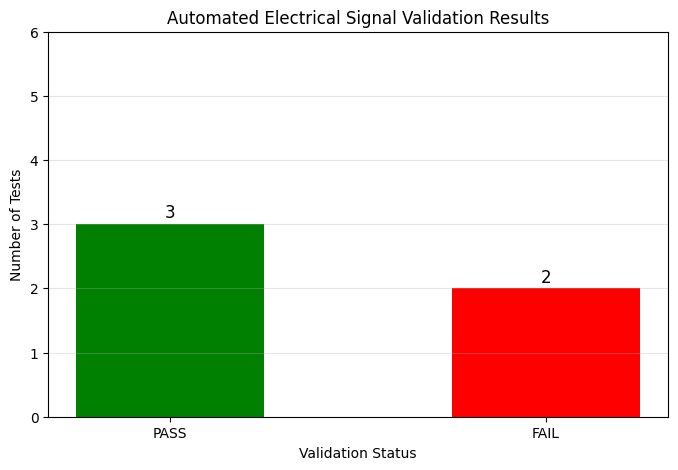

In [42]:
# Step 7.7: Visualize automated validation results

validation_counts = validation_df["Status"].value_counts()

statuses = ["PASS", "FAIL"]

counts = [
    validation_counts.get("PASS", 0),
    validation_counts.get("FAIL", 0)
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    statuses,
    counts,
    color=["green", "red"],
    width=0.5
)

plt.title("Automated Electrical Signal Validation Results")

plt.xlabel("Validation Status")
plt.ylabel("Number of Tests")

plt.ylim(0, total_tests + 1)

plt.grid(axis="y", alpha=0.3)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.1,
        f"{int(height)}",
        ha="center",
        fontsize=12
    )

plt.show()

In [43]:
# Step 7.8: Download generated engineering reports

from google.colab import files

files.download("electrical_signal_measurements.csv")

files.download("electrical_validation_results.csv")

files.download("electrical_validation_summary.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>